# Лабораторная работа №6
## Логистическая регрессия

**Выполнил:** Коршун Артём, группа P3319  
**Вариант:** 8, чётный номер в списке  
**Модуль:** 2. Методы машинного обучения

## Задание:

1. Выбрать один из предложенных датасетов:
   - Titanic — данные пассажиров Титаника.
   - Pima Indians Diabetes — данные о диабете.
2. Загрузить выбранные данные и подготовить их к обучению.
3. Рассчитать и графически показать статистику набора: число известных значений, среднее, стандартное отклонение, минимум, максимум и различные квантили.
4. Разделить данные на обучение и тест, самостоятельно выбрав подходящее соотношение.
5. Написать логистическую регрессию самостоятельно, используя для вычислений только NumPy и Pandas. Реализация должна включать:
   - sigmoid для расчёта вероятности;
   - функцию log loss;
   - обучение градиентным спуском;
   - настраиваемые learning rate и количество итераций.
6. Исследовать влияние гиперпараметров:
   - learning rate;
   - количества итераций;
   - способа оптимизации, например GD и метода Ньютона.
7. Для каждой комбинации параметров получить на test accuracy, precision, recall и F1.
8. Сделать выводы о подходящих настройках и объяснить изменения качества при их варьировании.

## Реализация:

### 1. Выбрать один из предложенных датасетов:

Беру Pima Indians Diabetes. Каждая строка — данные одной участницы исследования.

`Outcome` — результат проверки на диабет. Модель предсказывает этот результат по остальным восьми столбцам.

Входы — число беременностей (`Pregnancies`), глюкоза (`Glucose`), давление (`BloodPressure`), толщина кожи (`SkinThickness`), инсулин (`Insulin`), индекс массы тела (`BMI`), наследственный показатель (`DiabetesPedigreeFunction`) и возраст (`Age`). `Outcome` во входы не включаю.

### 2. Загрузить выбранные данные и подготовить их к обучению.

Проверяю размер, первые строки и количество ответов каждого класса.

In [19]:
import numpy as np
import pandas as pd

SEED = 8
TARGET = "Outcome"
df = pd.read_csv("data/diabetes.csv")
assert df.shape == (768, 9)
assert set(df[TARGET]) == {0, 1}
print("Размер исходной таблицы:", df.shape)
display(df.head())
display(df[TARGET].value_counts().sort_index().rename("Количество").to_frame())

Размер исходной таблицы: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Количество
Outcome,
0,500
1,268


Получено 768 строк и 9 столбцов: восемь входов и Outcome. Ответов 0 — 500, ответов 1 — 268.

Принимаю допущение: нули в `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` и `BMI` обозначают отсутствующие измерения. Заменяю их на `NaN`. Ноль в числе беременностей и метку `Outcome=0` сохраняю — это допустимые значения.

In [20]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)
X = df.drop(columns=TARGET)
y = df[TARGET].to_numpy(dtype=int)
missing_table = df.isna().sum().rename("Число пропусков").to_frame()
display(missing_table)
assert X.shape == (768, 8)
assert y.shape == (768,)
assert int(missing_table.loc["Glucose"].iloc[0]) == 5

,Число пропусков
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Больше всего пропусков у Insulin — 374. Чтобы не удалять неполные строки, заполняю NaN медианой — серединой известных значений столбца.

Сначала разделяю строки: медианы и масштабы должны определяться только по train. 

`stratified_split` возвращает номера строк двух частей, перемешивая каждый класс отдельно. Выделяю примерно 60% для train и по 20% для validation и test. Seed фиксирует состав частей.

In [21]:
def stratified_split(y, test_fraction, seed):
    rng = np.random.default_rng(seed)
    labels = np.asarray(y)
    train_ids, test_ids = [], []
    for label in np.unique(labels):
        ids = rng.permutation(np.flatnonzero(labels == label))
        n_test = max(1, round(len(ids) * test_fraction))
        test_ids.extend(ids[:n_test])
        train_ids.extend(ids[n_test:])
    return rng.permutation(train_ids), rng.permutation(test_ids)

pool_ids, test_ids = stratified_split(y, 0.2, SEED)
train_relative, val_relative = stratified_split(y[pool_ids], 0.25, SEED + 1)
train_ids, val_ids = pool_ids[train_relative], pool_ids[val_relative]
X_train_raw, X_val_raw, X_test_raw = [X.iloc[ids].copy() for ids in (train_ids, val_ids, test_ids)]
y_train, y_val, y_test = [y[ids] for ids in (train_ids, val_ids, test_ids)]

assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)
assert len(train_ids) + len(val_ids) + len(test_ids) == len(y)
split_table = pd.DataFrame([
    {"Часть": name, "Размер": len(labels), "Класс 0": int((labels == 0).sum()),
     "Класс 1": int((labels == 1).sum()), "Доля класса 1": float(labels.mean())}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
])

assert split_table["Размер"].tolist() == [460, 154, 154]

По train считаю медианы и передаю их в `fillna`: известные измерения сохраняются, заменяются только NaN. Затем меняю масштаб входов: `(значение − среднее train) / стандартное отклонение train`.

In [22]:
medians = X_train_raw.median()
assert medians.notna().all()
X_train_filled = X_train_raw.fillna(medians)
means = X_train_filled.mean()
stds = X_train_filled.std(ddof=0).replace(0, 1.0)

def transform(frame):
    scaled = ((frame.fillna(medians) - means) / stds).to_numpy(dtype=float)
    return np.column_stack([np.ones(len(scaled)), scaled])

X_train, X_val, X_test = [transform(frame) for frame in (X_train_raw, X_val_raw, X_test_raw)]
assert X_train.shape == (460, 9)
assert all(np.isfinite(matrix).all() for matrix in (X_train, X_val, X_test))
assert np.allclose(X_train[:, 1:].mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_train[:, 0], 1)
display(pd.DataFrame({"Медиана train": medians, "Среднее train после заполнения": means,
                      "Std train после заполнения": stds}).round(5))
print("Размеры матриц:", X_train.shape, X_val.shape, X_test.shape)

,Медиана train,Среднее train после заполнения,Std train после заполнения
Pregnancies,3.0000,3.75652,3.28128
Glucose,116.0000,120.38043,29.19695
BloodPressure,72.0000,71.73043,12.06167
SkinThickness,29.5000,29.37391,8.70397
Insulin,125.0000,142.15652,90.50000
BMI,32.8000,32.86174,6.85795
DiabetesPedigreeFunction,0.3725,0.48058,0.34513
Age,29.0000,33.02174,11.62865


Размеры матриц: (460, 9) (154, 9) (154, 9)


Пропусков после обработки нет. Ниже — те же реальные строки до заполнения, после него и после нормировки.

In [23]:
demo_columns = ["Glucose", "Insulin", "BMI"]
missing_mask = X_train_raw[demo_columns].isna().any(axis=1)
demo_ids = X_train_raw.index[missing_mask][:3].tolist()
demo_ids += X_train_raw.index[~missing_mask][:1].tolist()

before_demo = X_train_raw.loc[demo_ids, demo_columns].copy()
filled_demo = before_demo.fillna(medians[demo_columns])
scaled_demo = (filled_demo - means[demo_columns]) / stds[demo_columns]
processing_examples = pd.concat({
    "До заполнения": before_demo,
    "После заполнения": filled_demo,
    "После стандартизации": scaled_demo,
}, axis=1)
assert before_demo.isna().any().any()
assert filled_demo.notna().all().all()
assert not np.allclose(filled_demo.to_numpy(), scaled_demo.to_numpy())
display(processing_examples.round(4))

До заполнения               После заполнения                \
          Glucose Insulin   BMI          Glucose Insulin   BMI   
439         107.0     NaN  36.8            107.0   125.0  36.8   
734         105.0     NaN  23.3            105.0   125.0  23.3   
398          82.0     NaN  21.1             82.0   125.0  21.1   
515         163.0   105.0  31.6            163.0   105.0  31.6   

    После стандартизации                  
                 Glucose Insulin     BMI  
439              -0.4583 -0.1896  0.5743  
734              -0.5268 -0.1896 -1.3943  
398              -1.3145 -0.1896 -1.7151  
515               1.4597 -0.4106 -0.1840

В строке 439 Insulin меняется с NaN на медиану train 125, затем на −0.1896. Известный Glucose=107 при заполнении сохраняется, а при нормировке становится −0.4583. Заполнение заменяет отсутствующее измерение. Нормировка меняет масштаб всех входов. Для validation и test параметры не пересчитываются.

### 3. Рассчитать и графически показать статистику набора: число известных значений, среднее, стандартное отклонение, минимум, максимум и различные квантили.

Считаю статистику всех 768 строк. count — число известных значений, mean — среднее, std — разброс, min/max — крайние значения. 

In [24]:
statistics = X.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T
display(statistics.round(4))
assert statistics.loc["Pregnancies", "count"] == 768
assert statistics.loc["Glucose", "count"] == 763

,count,mean,std,min,10%,25%,50%,75%,90%,max
Pregnancies,768.0,3.8451,3.3696,0.000,0.000,1.0000,3.0000,6.0000,9.0000,17.00
Glucose,763.0,121.6868,30.5356,44.000,86.200,99.0000,117.0000,141.0000,167.0000,199.00
BloodPressure,733.0,72.4052,12.3822,24.000,58.000,64.0000,72.0000,80.0000,88.0000,122.00
SkinThickness,541.0,29.1534,10.4770,7.000,16.000,22.0000,29.0000,36.0000,42.0000,99.00
Insulin,394.0,155.5482,118.7759,14.000,50.300,76.2500,125.0000,190.0000,292.4000,846.00
BMI,757.0,32.4575,6.9250,18.200,24.000,27.5000,32.3000,36.6000,41.6200,67.10
DiabetesPedigreeFunction,768.0,0.4719,0.3313,0.078,0.165,0.2438,0.3725,0.6262,0.8786,2.42
Age,768.0,33.2409,11.7602,21.000,22.000,24.0000,29.0000,41.0000,51.0000,81.00


Гистограммы показывают распределения, столбчатые графики — количество, среднее, std и крайние значения, карта — квантили.

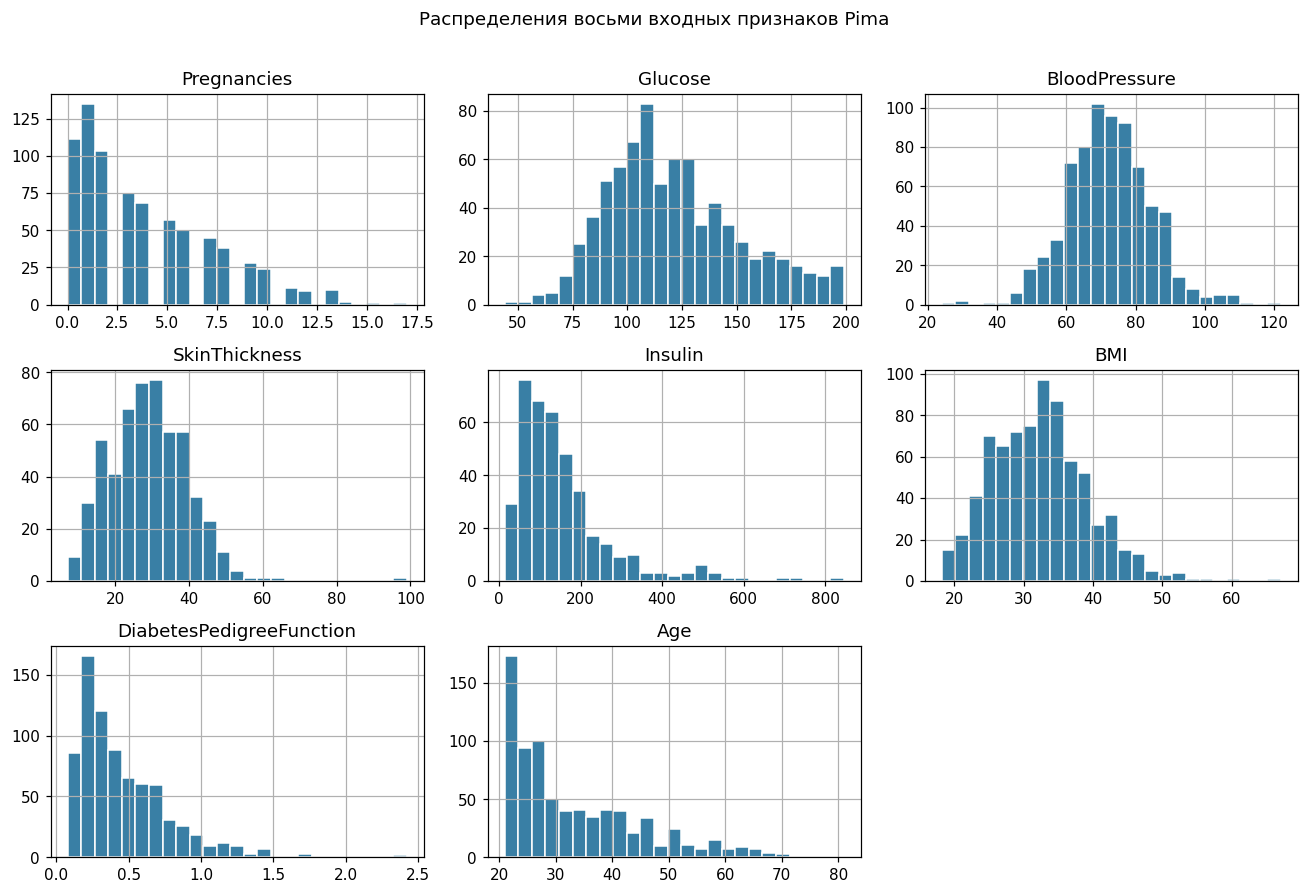

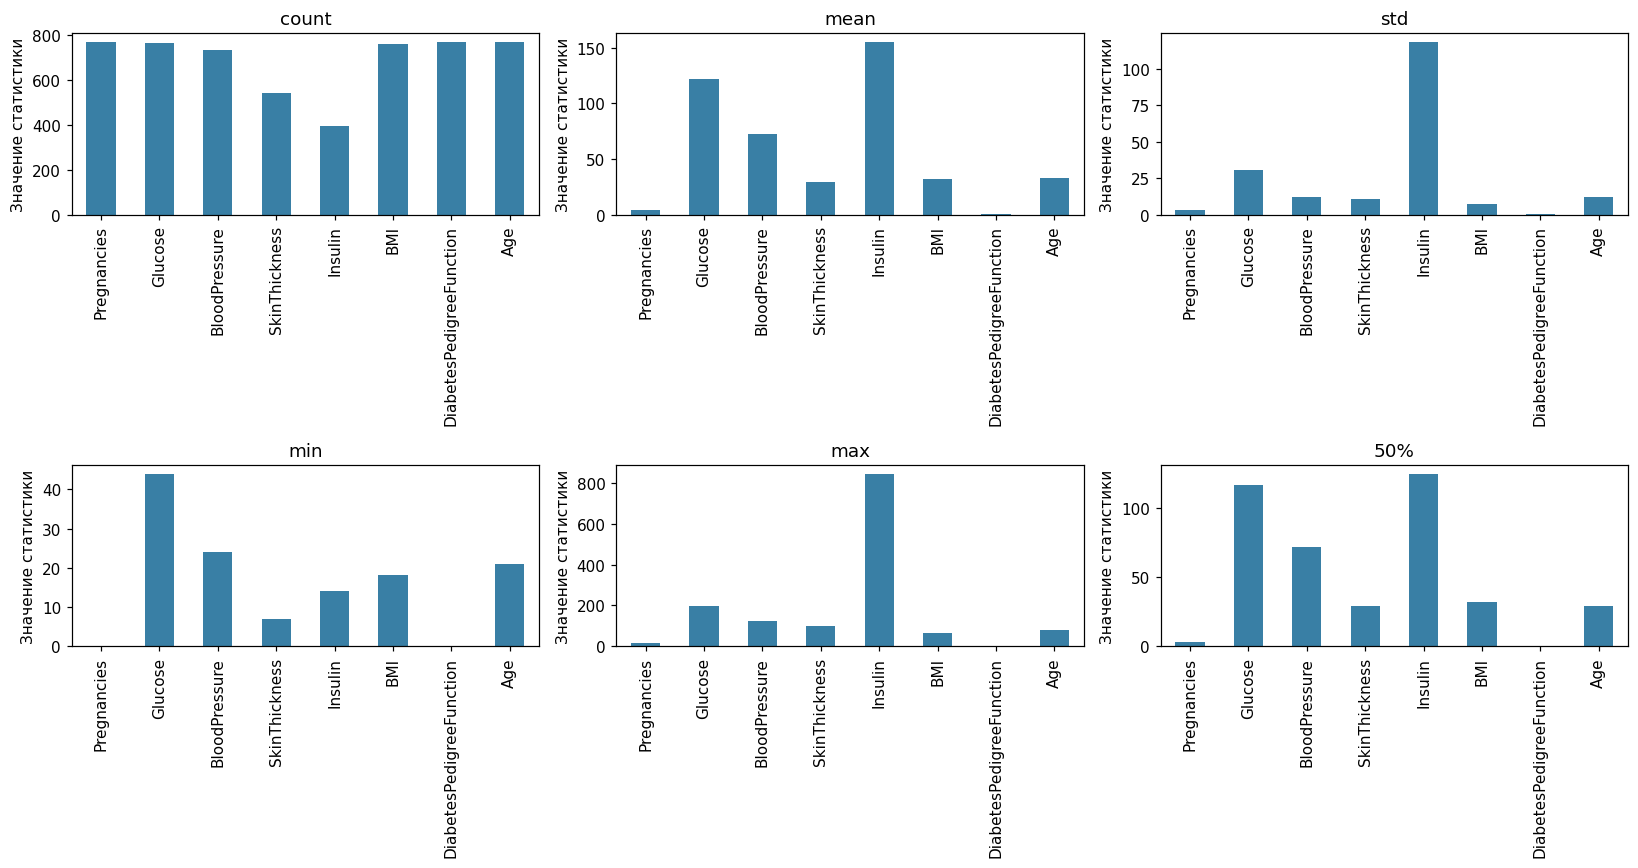

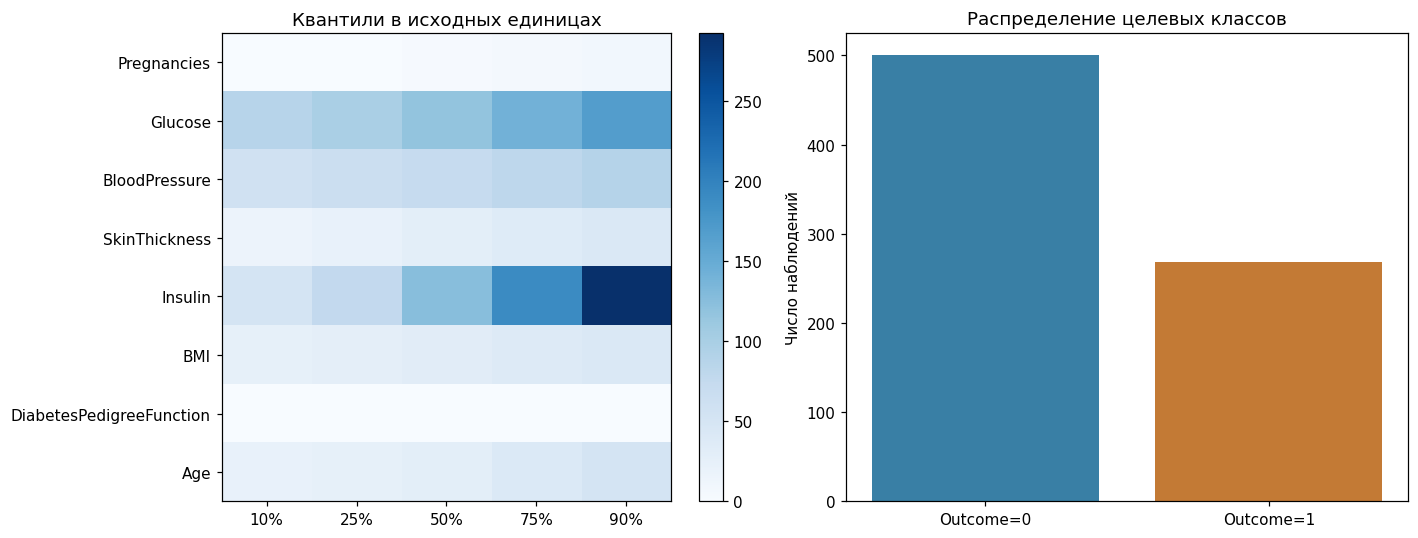

In [25]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
X.hist(bins=25, figsize=(12, 8), color="#397fa5", edgecolor="white")
plt.suptitle("Распределения восьми входных признаков Pima", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, statistic in zip(axes.flat, ["count", "mean", "std", "min", "max", "50%"]):
    statistics[statistic].plot.bar(ax=ax, title=statistic, color="#397fa5")
    ax.set_ylabel("Значение статистики")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
image = axes[0].imshow(statistics[["10%", "25%", "50%", "75%", "90%"]], aspect="auto", cmap="Blues")
axes[0].set_yticks(range(len(statistics)), labels=statistics.index)
axes[0].set_xticks(range(5), labels=["10%", "25%", "50%", "75%", "90%"])
axes[0].set_title("Квантили в исходных единицах")
fig.colorbar(image, ax=axes[0])
axes[1].bar(["Outcome=0", "Outcome=1"], [(y == 0).sum(), (y == 1).sum()], color=["#397fa5", "#c37a35"])
axes[1].set(title="Распределение целевых классов", ylabel="Число наблюдений")
plt.tight_layout()
plt.show()

У Insulin и DiabetesPedigreeFunction есть длинные правые хвосты: редкие измерения намного больше типичных. Поэтому среднее отличается от медианы, а масштабы входов перед обучением выравниваются.

### 4. Разделить данные на обучение и тест, самостоятельно выбрав подходящее соотношение.

Train нужен для обучения, validation — для выбора настроек, test — для проверки после выбора. Разделение уже выполнено до заполнения в пункте 2. Здесь проверяю размеры и отсутствие общих строк, не перемешивая данные повторно.

In [26]:
display(split_table)
assert len(train_ids) == 460
assert len(val_ids) == len(test_ids) == 154
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)
print("Разбиение сохранено: train=460, validation=154, test=154.")

,Часть,Размер,Класс 0,Класс 1,Доля класса 1
0,train,460,300,160,0.347826
1,validation,154,100,54,0.350649
2,test,154,100,54,0.350649


Разбиение сохранено: train=460, validation=154, test=154.


460 строк выделяю для обучения (`train`), 154 для выбора настроек (`validation`) и 154 для итоговой проверки (`test`).

### 5. Написать логистическую регрессию самостоятельно, используя для вычислений только NumPy и Pandas. Реализация должна включать:

- sigmoid для расчёта вероятности;
- функцию log loss;
- обучение градиентным спуском;
- настраиваемые learning rate и количество итераций.

Складываю взвешенные входы со свободным членом: `z = b + w₁ × x₁ + ... + w₈ × x₈`. Подобрать нужно девять весов по train.

Sigmoid превращает z в вероятность класса 1 от 0 до 1. 

Log loss сравнивает вероятности с правильными кодами и возвращает одну среднюю ошибку. Уверенный неверный ответ штрафуется сильнее.

`sigmoid(z)` возвращает вероятности. `logistic_gradient` показывает, как меняется ошибка при изменении каждого из девяти весов.

In [27]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1.0 + exp_z)
    return result

def log_loss_from_logits(y, z):
    return float(np.mean(np.logaddexp(0.0, z) - y * z))

def logistic_gradient(X, y, weights):
    return X.T @ (sigmoid(X @ weights) - y) / len(y)

assert np.allclose(sigmoid(np.array([-1000.0, 0.0, 1000.0])), [0, 0.5, 1])
assert np.isclose(log_loss_from_logits(np.array([0, 1]), np.array([0.0, 0.0])), np.log(2))
assert log_loss_from_logits(np.array([0, 1]), np.array([-10.0, 10.0])) < 0.001
print("Проверки sigmoid и log loss пройдены.")

Проверки sigmoid и log loss пройдены.


Проверяю перевод z в вероятность и метку, затем потерю при правильных кодах 0 и 1.

In [28]:
sigmoid_examples = pd.DataFrame({"Линейный ответ z": [-2.0, 0.0, 2.0]})
sigmoid_examples["Вероятность класса 1"] = sigmoid(sigmoid_examples["Линейный ответ z"].to_numpy())
sigmoid_examples["Метка при пороге 0.5"] = (sigmoid_examples["Вероятность класса 1"] >= 0.5).astype(int)
display(sigmoid_examples.round(6))

loss_examples = pd.DataFrame({"Правильный код y": [1, 1, 0, 0], "Линейный ответ z": [2.0, -2.0, -2.0, 2.0]})
demo_z = loss_examples["Линейный ответ z"].to_numpy()
demo_y = loss_examples["Правильный код y"].to_numpy()
loss_examples["Вероятность класса 1"] = sigmoid(demo_z)
loss_examples["Потеря одной строки"] = np.logaddexp(0.0, demo_z) - demo_y * demo_z
display(loss_examples.round(6))

,Линейный ответ z,Вероятность класса 1,Метка при пороге 0.5
0,-2.0,0.119203,0
1,0.0,0.500000,1
2,2.0,0.880797,1


,Правильный код y,Линейный ответ z,Вероятность класса 1,Потеря одной строки
0,1,2.0,0.880797,0.126928
1,1,-2.0,0.119203,2.126928
2,0,-2.0,0.119203,0.126928
3,0,2.0,0.880797,2.126928


При ответе 1 вероятность 0.881 даёт loss около 0.127, а вероятность 0.119 — около 2.127.

Градиент подсказывает, куда менять каждый вес для уменьшения общей ошибки. Проверяю его численно: немного увеличиваю и уменьшаю вес, пересчитываю loss и сравниваю разность с формулой производной.

In [29]:
probe_X, probe_y = X_train[:20], y_train[:20]
probe_weights = np.linspace(-0.1, 0.1, X_train.shape[1])
analytic = logistic_gradient(probe_X, probe_y, probe_weights)
numeric = np.empty_like(probe_weights)
epsilon = 1e-6
for j in range(len(probe_weights)):
    delta = np.zeros_like(probe_weights)
    delta[j] = epsilon
    plus = log_loss_from_logits(probe_y, probe_X @ (probe_weights + delta))
    minus = log_loss_from_logits(probe_y, probe_X @ (probe_weights - delta))
    numeric[j] = (plus - minus) / (2 * epsilon)
gradient_max_error = float(np.max(np.abs(analytic - numeric)))
assert np.allclose(analytic, numeric, atol=1e-6)
display(pd.DataFrame({"Аналитический": analytic, "Численный": numeric,
                      "Модуль разности": np.abs(analytic - numeric)}))
print(f"Максимальная ошибка градиента: {gradient_max_error:.3e}")

,Аналитический,Численный,Модуль разности
0,0.134781,0.134781,8.180151e-12
1,-0.243490,-0.243490,8.940487e-12
2,-0.305579,-0.305579,4.230805e-11
3,0.072119,0.072119,3.720357e-11
4,-0.096731,-0.096731,6.145355e-11
5,-0.190451,-0.190451,3.729600e-12
6,-0.168551,-0.168551,1.228095e-10
7,-0.029621,-0.029621,3.132426e-11
8,-0.152591,-0.152591,4.810535e-11


Максимальная ошибка градиента: 1.228e-10


Расхождение около 1.23 × 10⁻¹⁰: проверка производной прошла.

Градиентный спуск меняет веса так, чтобы уменьшить ошибку. На каждом обновлении вычитаю из весов градиент, умноженный на `learning_rate`. Чем больше `learning_rate`, тем больше шаг. `iterations` задаёт максимум обновлений.

In [30]:
def fit_logistic(X, y, learning_rate=0.1, iterations=200, tol=1e-7, *, update_direction=None):
    if learning_rate <= 0 or iterations < 1:
        raise ValueError("Нужны положительный шаг и хотя бы одна итерация")
    weights = np.zeros(X.shape[1], dtype=float)
    history = [log_loss_from_logits(y, X @ weights)]
    for _ in range(iterations):
        gradient = logistic_gradient(X, y, weights)
        if np.max(np.abs(gradient)) < tol:
            break
        direction = gradient
        if update_direction is not None:
            direction = update_direction(X, weights, gradient)
        weights = weights - learning_rate * direction
        loss = log_loss_from_logits(y, X @ weights)
        if not np.isfinite(weights).all() or not np.isfinite(loss):
            raise FloatingPointError("Неконечные значения в ходе обучения")
        history.append(loss)
    return {"weights": weights, "history": history, "n_iter": len(history) - 1}

def predict_proba(model, X):
    return sigmoid(X @ model["weights"])

print("Реализованы градиентный спуск и предсказание вероятностей.")

Реализованы градиентный спуск и предсказание вероятностей.


`fit_logistic` получает входы, ответы и настройки. Она возвращает веса, историю ошибки и число обновлений. `predict_proba` применяет готовые веса.

Начальные веса нулевые: z=0, вероятность 0.5. Во всех опытах вероятность не меньше 0.5 даёт код 1, иначе 0. Порог один, чтобы сравнивать настройки обучения, не меняя одновременно правило ответа.

### 6. Исследовать влияние гиперпараметров:

- learning rate;
- количества итераций;
- способа оптимизации, например GD и метода Ньютона.

Сравниваю градиентный спуск (`gd`) с методом Ньютона (`newton`). Ньютон учитывает, как меняется градиент, и по этому рассчитывает обновление весов. Для него передаю в `fit_logistic` функцию `newton_direction`.

Для каждого метода пробую шаги 0.01, 0.1 и 1.0 и максимум 10, 50 и 200 обновлений. Всего 18 сочетаний на одном разбиении данных.

Для выбора использую F1 на validation. Эта оценка учитывает, сколько настоящих единиц модель нашла и сколько ложных единиц выдала. При одинаковом F1 выбираю меньший log loss, затем первое имя настройки по алфавиту. Test оставляю для следующего пункта.

In [31]:
def confusion_counts(y_true, y_pred):
    tp = tn = fp = fn = 0
    for actual, predicted in zip(y_true, y_pred):
        if actual == 1 and predicted == 1:
            tp += 1
        elif actual == 0 and predicted == 0:
            tn += 1
        elif actual == 0 and predicted == 1:
            fp += 1
        else:
            fn += 1
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn}

def classification_metrics(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    tp, tn, fp, fn = [counts[name] for name in ("TP", "TN", "FP", "FN")]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "accuracy": (tp + tn) / len(y_true),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
    }

assert classification_metrics([0, 0, 1, 1], [0, 1, 0, 1])["f1"] == 0.5
assert classification_metrics([0, 1], [0, 0])["precision"] == 0.0
print("Проверки собственных метрик пройдены.")

Проверки собственных метрик пройдены.


`classification_metrics` сравнивает правильные и предсказанные классы. В таблице `iterations` — заданное количество итераций, `n_iter` — сколько обновлений выполнилось, `train_loss` — ошибка на обучении. Столбцы с `val_` относятся к `validation`.

In [32]:
def newton_direction(X, weights, gradient):
    probabilities = sigmoid(X @ weights)
    curvature = probabilities * (1.0 - probabilities)
    hessian = X.T @ (curvature[:, None] * X) / len(X)
    return np.linalg.solve(hessian + 1e-8 * np.eye(X.shape[1]), gradient)

models, validation_rows = {}, []
for method, update_direction in [("gd", None), ("newton", newton_direction)]:
    for learning_rate in [0.01, 0.1, 1.0]:
        for iterations in [10, 50, 200]:
            run_id = f"{method}_lr{learning_rate}_n{iterations}"
            model = fit_logistic(
                X_train, y_train, learning_rate, iterations, update_direction=update_direction
            )
            models[run_id] = model
            probabilities = predict_proba(model, X_val)
            row = {
                "run_id": run_id, "method": method, "learning_rate": learning_rate,
                "iterations": iterations, "n_iter": model["n_iter"],
                "train_loss": model["history"][-1],
                "val_loss": log_loss_from_logits(y_val, X_val @ model["weights"]),
            }
            for name, value in classification_metrics(y_val, (probabilities >= 0.5).astype(int)).items():
                row[f"val_{name}"] = value
            validation_rows.append(row)

validation_table = pd.DataFrame(validation_rows).sort_values(
    ["val_f1", "val_loss", "run_id"], ascending=[False, True, True]
).reset_index(drop=True)
best_run_id = str(validation_table.iloc[0]["run_id"])
assert len(models) == len(validation_table) == 18
assert all(model["history"][-1] < model["history"][0] for model in models.values())
display(validation_table.round(6))
print("Конфигурация выбрана до оценки test:", best_run_id)

,run_id,method,learning_rate,iterations,n_iter,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1
0,newton_lr0.1_n10,newton,0.10,10,10,0.515776,0.453510,0.831169,0.833333,0.648148,0.729167
1,newton_lr1.0_n10,newton,1.00,10,5,0.474134,0.370733,0.824675,0.800000,0.666667,0.727273
2,newton_lr1.0_n200,newton,1.00,200,5,0.474134,0.370733,0.824675,0.800000,0.666667,0.727273
3,newton_lr1.0_n50,newton,1.00,50,5,0.474134,0.370733,0.824675,0.800000,0.666667,0.727273
4,newton_lr0.1_n200,newton,0.10,200,140,0.474134,0.370733,0.824675,0.800000,0.666667,0.727273
5,gd_lr1.0_n200,gd,1.00,200,200,0.474134,0.370733,0.824675,0.800000,0.666667,0.727273
6,newton_lr0.1_n50,newton,0.10,50,50,0.474150,0.371633,0.824675,0.800000,0.666667,0.727273
7,gd_lr1.0_n50,gd,1.00,50,50,0.474180,0.371681,0.824675,0.800000,0.666667,0.727273
8,gd_lr0.1_n200,gd,0.10,200,200,0.476558,0.379425,0.824675,0.813953,0.648148,0.721649
9,newton_lr0.01_n50,newton,0.01,50,50,0.571568,0.531735,0.824675,0.813953,0.648148,0.721649


Конфигурация выбрана до оценки test: newton_lr0.1_n10


Выбран `newton_lr0.1_n10`: validation F1=0.729167, loss=0.453510. У Ньютона с шагом 1 loss ниже, но F1=0.727273. Критерии разные: F1 сравнивает коды после порога, log loss — вероятности. Поэтому меньшая loss не меняет победителя, выбранного по F1.

Слева градиентный спуск, справа Ньютон. Цвет показывает размер шага `lr`. Вверху видно, как падает ошибка на обучении после каждого обновления. Внизу каждая точка показывает F1 на `validation` при заданном количестве итераций.

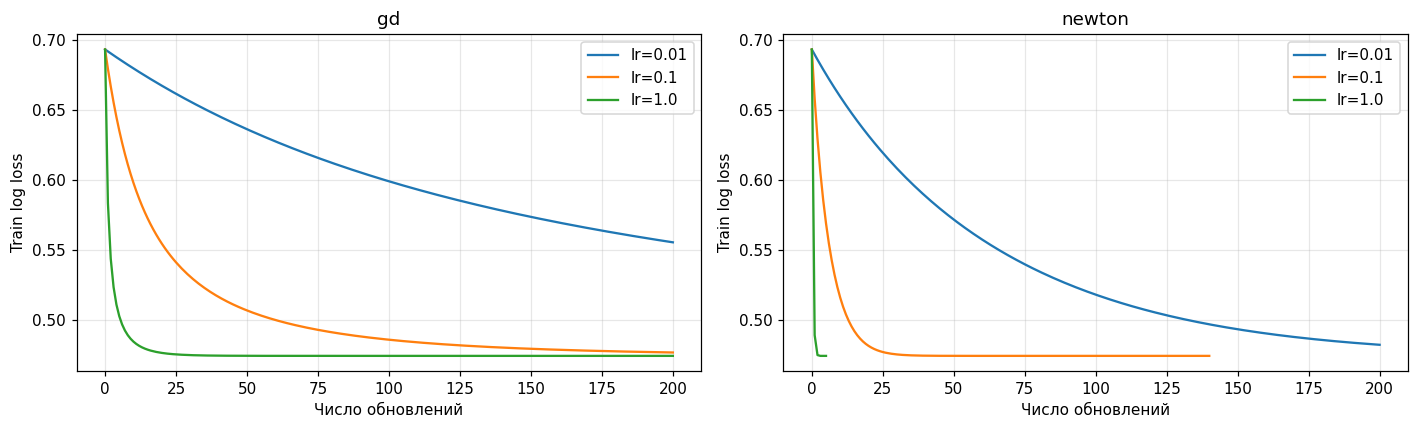

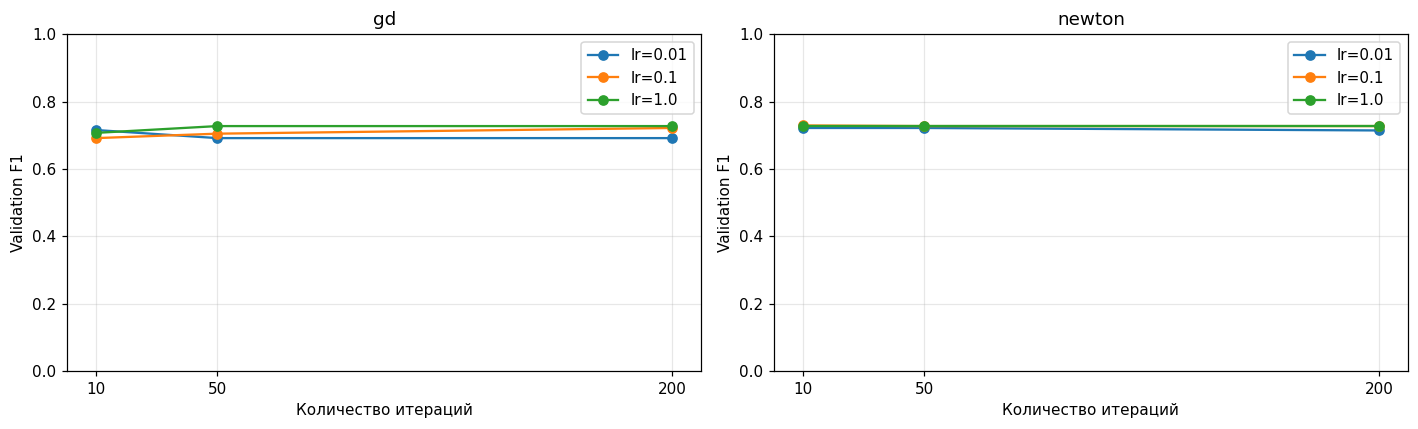

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method, ax in zip(["gd", "newton"], axes):
    for learning_rate in [0.01, 0.1, 1.0]:
        run_id = f"{method}_lr{learning_rate}_n200"
        ax.plot(models[run_id]["history"], label=f"lr={learning_rate}")
    ax.set(title=method, xlabel="Число обновлений", ylabel="Train log loss")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method, ax in zip(["gd", "newton"], axes):
    part = validation_table[validation_table["method"] == method]
    for learning_rate in [0.01, 0.1, 1.0]:
        curve = part[part["learning_rate"] == learning_rate].sort_values("iterations")
        ax.plot(curve["iterations"], curve["val_f1"], marker="o", label=f"lr={learning_rate}")
    ax.set(title=method, xlabel="Количество итераций", ylabel="Validation F1",
           xticks=[10, 50, 200], ylim=(0, 1))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

При шаге 1 Ньютон остановился после 5 обновлений, когда градиент стал очень маленьким. У градиентного спуска после 200 обновлений почти та же ошибка на обучении (около 0.4741). Внизу видно, что F1 при разных настройках меняется слабо.

### 7. Для каждой комбинации параметров получить на test accuracy, precision, recall и F1.

Проверяю все 18 моделей на одних 154 test-строках. Победитель уже выбран по validation. TP/TN — верные единицы/нули, FP — ложная единица, FN — пропущенная единица.

In [34]:
test_rows = []
for run_id, model in models.items():
    probabilities = predict_proba(model, X_test)
    predictions = (probabilities >= 0.5).astype(int)
    row = {"run_id": run_id}
    for name, value in classification_metrics(y_test, predictions).items():
        row[f"test_{name}"] = value
    test_rows.append(row)
results = validation_table.merge(pd.DataFrame(test_rows), on="run_id", validate="one_to_one")
metric_columns = ["test_accuracy", "test_precision", "test_recall", "test_f1"]
assert len(results) == 18
assert results[metric_columns].ge(0).all().all() and results[metric_columns].le(1).all().all()
display(results[["run_id", "method", "learning_rate", "iterations", "n_iter"] + metric_columns].round(6))

selected_row = results.loc[results["run_id"] == best_run_id].iloc[0]
selected_model = models[best_run_id]
selected_probability = predict_proba(selected_model, X_test)
selected_prediction = (selected_probability >= 0.5).astype(int)
selected_counts = confusion_counts(y_test, selected_prediction)
baseline = classification_metrics(y_test, np.zeros_like(y_test))
display(pd.DataFrame([
    {"Модель": "Выбрана по validation", **classification_metrics(y_test, selected_prediction)},
    {"Модель": "Всегда 0", **baseline},
]).set_index("Модель").round(6))
display(pd.Series(selected_counts, name="Число исходов").to_frame())

,run_id,method,learning_rate,iterations,n_iter,test_accuracy,test_precision,test_recall,test_f1
0,newton_lr0.1_n10,newton,0.10,10,10,0.759740,0.680851,0.592593,0.633663
1,newton_lr1.0_n10,newton,1.00,10,5,0.759740,0.680851,0.592593,0.633663
2,newton_lr1.0_n200,newton,1.00,200,5,0.759740,0.680851,0.592593,0.633663
3,newton_lr1.0_n50,newton,1.00,50,5,0.759740,0.680851,0.592593,0.633663
4,newton_lr0.1_n200,newton,0.10,200,140,0.759740,0.680851,0.592593,0.633663
5,gd_lr1.0_n200,gd,1.00,200,200,0.759740,0.680851,0.592593,0.633663
6,newton_lr0.1_n50,newton,0.10,50,50,0.759740,0.680851,0.592593,0.633663
7,gd_lr1.0_n50,gd,1.00,50,50,0.759740,0.680851,0.592593,0.633663
8,gd_lr0.1_n200,gd,0.10,200,200,0.766234,0.687500,0.611111,0.647059
9,newton_lr0.01_n50,newton,0.01,50,50,0.759740,0.680851,0.592593,0.633663


,accuracy,precision,recall,f1
Модель,,,,
Выбрана по validation,0.759740,0.680851,0.592593,0.633663
Всегда 0,0.649351,0.000000,0.000000,0.000000


,Число исходов
TP,32
TN,85
FP,15
FN,22


У выбранной модели TP=32, TN=85, FP=15, FN=22. Accuracy=117/154=0.759740: верны 117 ответов. Precision=32/47=0.680851: из 47 предсказанных единиц 32 настоящие. Recall=32/54=0.592593: найдены 32 из 54 настоящих единиц, 22 пропущены.

F1 = `2 × precision × recall / (precision + recall)` = 0.633663. Она учитывает обе доли и снижается, если хотя бы одна мала. Все четыре метрики каждой комбинации приведены выше.

Ориентир «всегда 0» угадывает 100 из 154 строк: accuracy=0.649351, но F1=0, потому что единицы не найдены.

Ниже — применение выбранной модели к пяти test-строкам с сохранённой обработкой train.

In [35]:
example_input = X_test_raw.head(5).copy()
example_matrix = transform(example_input)
example_probability = predict_proba(selected_model, example_matrix)
example = example_input.reset_index(drop=True)
example["Фактический Outcome"] = y_test[:5]
example["P(Outcome=1)"] = example_probability
example["Предсказание"] = (example_probability >= 0.5).astype(int)
display(example.round(5))

coefficients = pd.Series(selected_model["weights"], index=["Свободный член"] + X.columns.tolist(),
                         name="Вес в стандартизованном масштабе")
display(coefficients.round(6).to_frame())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Фактический Outcome,P(Outcome=1),Предсказание
0,6,151.0,62.0,31.0,120.0,35.5,0.692,28,0,0.63376,1
1,0,74.0,52.0,10.0,36.0,27.8,0.269,22,0,0.13109,0
2,4,144.0,58.0,28.0,140.0,29.5,0.287,37,0,0.46374,0
3,0,100.0,70.0,26.0,50.0,30.8,0.597,21,0,0.24636,0
4,0,101.0,62.0,NaN,NaN,21.9,0.336,25,0,0.16508,0


,Вес в стандартизованном масштабе
Свободный член,-0.438871
Pregnancies,0.224554
Glucose,0.572528
BloodPressure,-0.027871
SkinThickness,0.018092
Insulin,-0.074783
BMI,0.292743
DiabetesPedigreeFunction,0.168973
Age,0.062533


`P(Outcome=1)` — вероятность, `Предсказание` — код после порога 0.5. Веса относятся к нормированным входам и сами вероятностями не являются.

### 8. Сделать выводы о подходящих настройках и объяснить изменения качества при их варьировании.

Собираю результаты выбранной конфигурации и наблюдения по экспериментам.

In [36]:
newton_full = models["newton_lr1.0_n200"]
gd_full = models["gd_lr1.0_n200"]
print("Выбранная конфигурация:", best_run_id)
print(f"Validation F1: {float(selected_row['val_f1']):.9f}")
print(f"Validation log loss: {float(selected_row['val_loss']):.9f}")
for name in metric_columns:
    print(f"{name}: {float(selected_row[name]):.9f}")
print(f"Baseline accuracy: {baseline['accuracy']:.9f}")
print(f"Baseline F1: {baseline['f1']:.9f}")
print("Ошибки выбранной модели:", selected_counts)
print(f"Newton lr=1: {newton_full['n_iter']} шагов, loss={newton_full['history'][-1]:.9f}")
print(f"GD lr=1: {gd_full['n_iter']} шагов, loss={gd_full['history'][-1]:.9f}")
print(f"Ошибка проверки градиента: {gradient_max_error:.3e}")
assert best_run_id == str(validation_table.iloc[0]["run_id"])
assert len(results) == 18

Выбранная конфигурация: newton_lr0.1_n10
Validation F1: 0.729166667
Validation log loss: 0.453509943
test_accuracy: 0.759740260
test_precision: 0.680851064
test_recall: 0.592592593
test_f1: 0.633663366
Baseline accuracy: 0.649350649
Baseline F1: 0.000000000
Ошибки выбранной модели: {'TP': 32, 'TN': 85, 'FP': 15, 'FN': 22}
Newton lr=1: 5 шагов, loss=0.474133700
GD lr=1: 200 шагов, loss=0.474133700
Ошибка проверки градиента: 1.228e-10


Лучший F1 на `validation` получен у Ньютона с шагом 0.1 и 10 итерациями. На test модель лучше ориентира «всегда 0», но пропускает 22 из 54 положительных примеров.

При маленьком шаге больше итераций помогают снизить ошибку на обучении. Ньютон требует меньше обновлений, однако время здесь не сравнивалось. Меньшая log loss не гарантирует лучшего F1 после порога.

На тесте выбранная модель дала 117 правильных ответов из 154, то есть accuracy около 76%. Из 54 положительных случаев она нашла 32, поэтому recall около 59%. Всего модель выдала 47 положительных ответов, из них 32 были верными. Это precision около 68%. Вместе эти две оценки дают F1 около 0.63.

Если всем ставить 0, получится около 65% правильных ответов. Наша модель угадывает чаще и находит положительные случаи, хотя 22 из 54 всё ещё пропускает.

Выводы относятся к этому разбиению и 18 настройкам. Медиана приближённо заменяет неизвестные измерения, а линейная модель может не учесть сложные взаимодействия.